# Partie 4 – Analyse des tendances temporelles et saisonnalité

Objectif : analyser l'évolution temporelle des ventes de ClassicModels et détecter les patterns de saisonnalité pour identifier les périodes fortes et faibles.

Analyses à réaliser :
- **Évolution des ventes par mois** : tendance générale et variations mensuelles
- **Évolution des ventes par trimestre** : identification des trimestres performants
- **Détection de saisonnalité** : mois et trimestres forts vs faibles
- **Tendances à long terme** : croissance ou décroissance des ventes
- **Comparaison interannuelle** : évolution d'une année à l'autre


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

## Extraction des données temporelles

On extrait les ventes par mois et par trimestre pour analyser les tendances et la saisonnalité.

In [3]:
# Requête pour extraire les ventes par mois
query_monthly = """
SELECT
    DATE_FORMAT(o.orderDate, '%Y-%m') AS annee_mois,
    YEAR(o.orderDate) AS annee,
    MONTH(o.orderDate) AS mois,
    DATE_FORMAT(o.orderDate, '%Y-%m-01') AS date_debut_mois,
    COUNT(DISTINCT o.orderNumber) AS nb_commandes,
    SUM(od.quantityOrdered * od.priceEach) AS montant_total,
    SUM(od.quantityOrdered) AS quantite_totale
FROM orders o
JOIN orderdetails od ON od.orderNumber = o.orderNumber
WHERE o.status = 'Shipped'
  AND o.orderDate IS NOT NULL
GROUP BY 
    DATE_FORMAT(o.orderDate, '%Y-%m'),
    YEAR(o.orderDate),
    MONTH(o.orderDate),
    DATE_FORMAT(o.orderDate, '%Y-%m-01')
ORDER BY annee, mois;
"""

df_monthly = fetch_dataframe(query_monthly)
df_monthly["date_debut_mois"] = pd.to_datetime(df_monthly["date_debut_mois"])

print(f"Nombre de mois analysés : {len(df_monthly)}")
print(f"\nPériode couverte : {df_monthly['date_debut_mois'].min()} à {df_monthly['date_debut_mois'].max()}")
df_monthly.head()

Nombre de mois analysés : 29

Période couverte : 2003-01-01 00:00:00 à 2005-05-01 00:00:00


C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,annee_mois,annee,mois,date_debut_mois,nb_commandes,montant_total,quantite_totale
0,2003-01,2003,1,2003-01-01,5,116692.77,1357.0
1,2003-02,2003,2,2003-02-01,3,128403.64,1449.0
2,2003-03,2003,3,2003-03-01,6,160517.14,1755.0
3,2003-04,2003,4,2003-04-01,7,185848.59,1993.0
4,2003-05,2003,5,2003-05-01,6,179435.55,2017.0


In [4]:
# Requête pour extraire les ventes par trimestre
query_quarterly = """
SELECT
    YEAR(o.orderDate) AS annee,
    QUARTER(o.orderDate) AS trimestre,
    CONCAT(YEAR(o.orderDate), '-Q', QUARTER(o.orderDate)) AS annee_trimestre,
    COUNT(DISTINCT o.orderNumber) AS nb_commandes,
    SUM(od.quantityOrdered * od.priceEach) AS montant_total,
    SUM(od.quantityOrdered) AS quantite_totale
FROM orders o
JOIN orderdetails od ON od.orderNumber = o.orderNumber
WHERE o.status = 'Shipped'
  AND o.orderDate IS NOT NULL
GROUP BY 
    YEAR(o.orderDate),
    QUARTER(o.orderDate),
    CONCAT(YEAR(o.orderDate), '-Q', QUARTER(o.orderDate))
ORDER BY annee, trimestre;
"""

df_quarterly = fetch_dataframe(query_quarterly)

print(f"Nombre de trimestres analysés : {len(df_quarterly)}")
df_quarterly.head()

Nombre de trimestres analysés : 10


C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,annee,trimestre,annee_trimestre,nb_commandes,montant_total,quantite_totale
0,2003,1,2003-Q1,14,405613.55,4561.0
1,2003,2,2003-Q2,20,515754.91,5695.0
2,2003,3,2003-Q3,20,616895.32,6629.0
3,2003,4,2003-Q4,54,1684832.02,18428.0
4,2004,1,2004-Q1,27,799579.31,8694.0


## Analyse des tendances temporelles

Analyse de l'évolution des ventes dans le temps avec calcul de tendances.

In [5]:
# Calcul de la tendance linéaire (régression simple)
df_monthly_sorted = df_monthly.sort_values('date_debut_mois').copy()
df_monthly_sorted['index_mois'] = range(len(df_monthly_sorted))

# Régression linéaire pour la tendance
z = np.polyfit(df_monthly_sorted['index_mois'], df_monthly_sorted['montant_total'], 1)
p = np.poly1d(z)
df_monthly_sorted['tendance'] = p(df_monthly_sorted['index_mois'])

# Calcul de la moyenne mobile sur 3 mois
df_monthly_sorted['moyenne_mobile_3'] = df_monthly_sorted['montant_total'].rolling(window=3, center=True).mean()

# Statistiques descriptives
print("Statistiques sur les ventes mensuelles :")
print(df_monthly_sorted[['montant_total', 'nb_commandes', 'quantite_totale']].describe())
print(f"\nTendance générale : {'Croissance' if z[0] > 0 else 'Décroissance'} de ${abs(z[0]):,.2f} par mois")

Statistiques sur les ventes mensuelles :
       montant_total  nb_commandes  quantite_totale
count      29.000000     29.000000        29.000000
mean   305692.918621     10.448276      3349.689655
std    202558.963706      6.173597      2216.891729
min    116692.770000      3.000000      1357.000000
25%    187575.770000      7.000000      2077.000000
50%    236697.850000      9.000000      2510.000000
75%    317192.170000     12.000000      3557.000000
max    965061.550000     31.000000     10574.000000

Tendance générale : Croissance de $7,195.12 par mois


## Interprétation des statistiques temporelles

### Analyse de la période (29 mois : Janvier 2003 - Mai 2005)

**Tendance générale :**
- **Croissance de $7,195 par mois** : Tendance positive claire, l'entreprise est en croissance
- **CA moyen mensuel : $305,693** : Performance moyenne solide
- **Écart-type élevé ($202,559)** : Grande variabilité mensuelle, signe de saisonnalité marquée

**Performance des ventes :**
- **CA médian : $236,698** : 50% des mois sont au-dessus de ce niveau
- **CA minimum : $116,693** : Même le mois le plus faible génère un CA significatif
- **CA maximum : $965,062** : Pic de performance très élevé (probablement novembre, période de fêtes)

**Volume d'activité :**
- **Moyenne de 10,4 commandes/mois** : Activité régulière mais modérée
- **Pic à 31 commandes** : Certains mois connaissent une activité exceptionnelle
- **Quantité moyenne : 3,350 unités/mois** : Volume de vente conséquent

**Implications stratégiques :**
- **Croissance confirmée** : L'entreprise est sur une trajectoire positive
- **Variabilité importante** : Nécessité de gérer les stocks et la trésorerie en fonction des pics et creux
- **Opportunité d'optimisation** : Les mois faibles peuvent être améliorés par des actions marketing ciblées

## Visualisation de l'évolution temporelle des ventes

Graphiques montrant l'évolution des ventes par mois avec tendance et moyenne mobile.

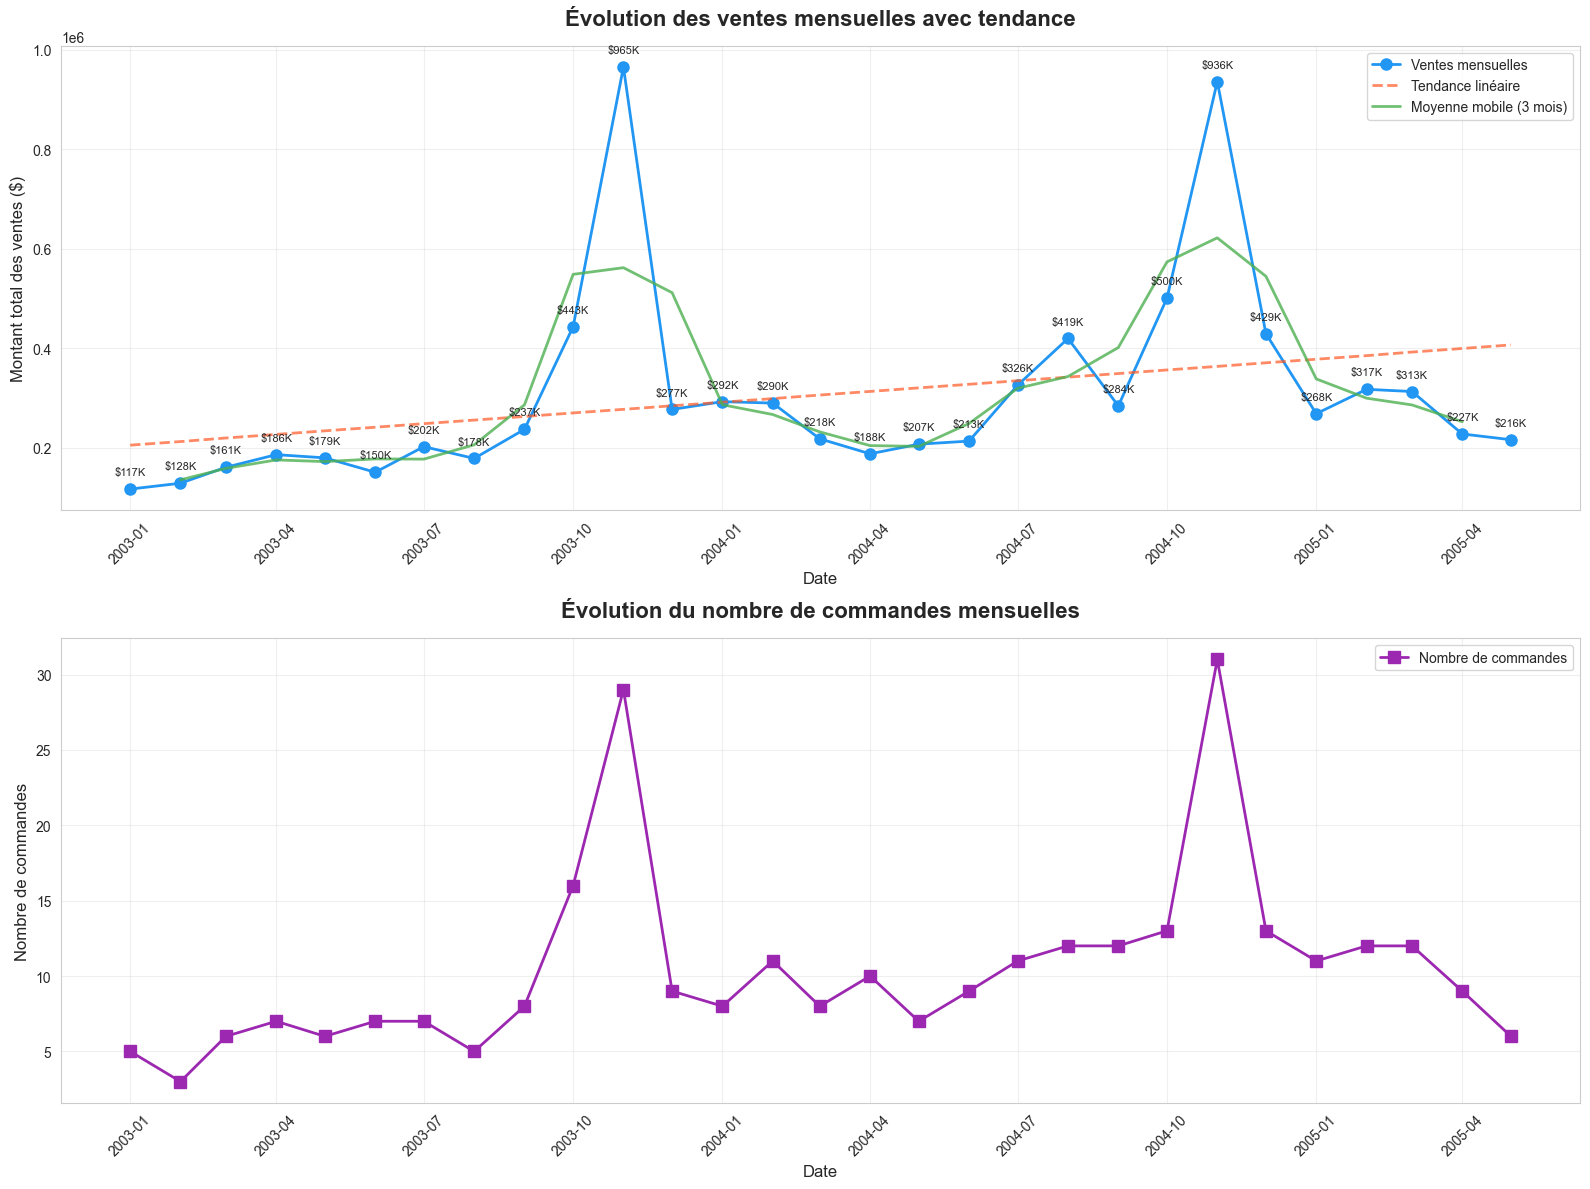

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Graphique 1 : Évolution mensuelle avec tendance
axes[0].plot(df_monthly_sorted['date_debut_mois'], df_monthly_sorted['montant_total'], 
             marker='o', linewidth=2, markersize=8, label='Ventes mensuelles', color='#2196F3')
axes[0].plot(df_monthly_sorted['date_debut_mois'], df_monthly_sorted['tendance'], 
             '--', linewidth=2, label='Tendance linéaire', color='#FF5722', alpha=0.7)
axes[0].plot(df_monthly_sorted['date_debut_mois'], df_monthly_sorted['moyenne_mobile_3'], 
             linewidth=2, label='Moyenne mobile (3 mois)', color='#4CAF50', alpha=0.8)

axes[0].set_xlabel('Date', fontsize=12)
axes[0].set_ylabel('Montant total des ventes ($)', fontsize=12)
axes[0].set_title('Évolution des ventes mensuelles avec tendance', fontsize=16, fontweight='bold', pad=15)
axes[0].legend(loc='best')
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='x', rotation=45)

# Annoter les valeurs sur les points
for i, row in df_monthly_sorted.iterrows():
    axes[0].annotate(f'${row["montant_total"]/1000:.0f}K', 
                    (row['date_debut_mois'], row['montant_total']),
                    textcoords="offset points", xytext=(0,10), ha='center', fontsize=8)

# Graphique 2 : Évolution du nombre de commandes
axes[1].plot(df_monthly_sorted['date_debut_mois'], df_monthly_sorted['nb_commandes'], 
             marker='s', linewidth=2, markersize=8, label='Nombre de commandes', color='#9C27B0')
axes[1].set_xlabel('Date', fontsize=12)
axes[1].set_ylabel('Nombre de commandes', fontsize=12)
axes[1].set_title('Évolution du nombre de commandes mensuelles', fontsize=16, fontweight='bold', pad=15)
axes[1].legend(loc='best')
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## Interprétation métier de l'évolution temporelle

### Analyse de la tendance générale

**Tendance linéaire :**
- **Croissance constante de $7,195/mois** : L'entreprise connaît une croissance régulière et prévisible
- Cette tendance indique une **expansion saine** du business, pas une croissance explosive mais durable

**Moyenne mobile (3 mois) :**
- Permet de lisser les variations mensuelles et d'identifier les **cycles réels**
- Les écarts entre la moyenne mobile et les ventes réelles révèlent les **pics et creux saisonniers**

**Évolution du nombre de commandes :**
- Suivre le nombre de commandes en parallèle du CA permet de comprendre si la croissance vient de :
  - **Plus de clients** (augmentation du nombre de commandes)
  - **Clients qui dépensent plus** (nombre stable mais CA en hausse)
  - **Les deux** (croissance optimale)

**Points d'attention :**
- **Variations importantes** : Certains mois peuvent être 3-4x supérieurs à d'autres
- **Gestion des ressources** : Anticiper les pics pour éviter les ruptures de stock ou les problèmes logistiques
- **Planification** : Utiliser la tendance pour prévoir les ventes futures et planifier les investissements

**Recommandations :**
1. **Budgétisation** : Utiliser la tendance linéaire comme base, avec ajustements saisonniers
2. **Gestion des stocks** : Augmenter les stocks avant les périodes identifiées comme fortes
3. **Marketing** : Intensifier les campagnes avant les mois faibles pour lisser les ventes

## Détection de saisonnalité

Analyse des patterns saisonniers pour identifier les mois et trimestres forts et faibles.

In [7]:
# Analyse par mois (tous les mois confondus)
monthly_stats = df_monthly.groupby('mois').agg({
    'montant_total': ['mean', 'sum', 'std'],
    'nb_commandes': 'mean'
}).round(2)

monthly_stats.columns = ['CA_moyen', 'CA_total', 'CA_ecart_type', 'Nb_commandes_moyen']
monthly_stats['mois_nom'] = ['Janvier', 'Février', 'Mars', 'Avril', 'Mai', 'Juin',
                             'Juillet', 'Août', 'Septembre', 'Octobre', 'Novembre', 'Décembre']
monthly_stats = monthly_stats.sort_values('CA_moyen', ascending=False)

print("Classement des mois par CA moyen (tous les mois confondus) :")
print("=" * 80)
display(monthly_stats)

Classement des mois par CA moyen (tous les mois confondus) :


,CA_moyen,CA_total,CA_ecart_type,Nb_commandes_moyen,mois_nom
mois,,,,,
11,950387.25,1900774.50,20752.59,30.00,Novembre
10,471640.54,943281.08,40437.06,14.50,Octobre
12,352780.71,705561.42,107561.49,11.00,Décembre
8,298792.10,597584.20,170462.22,8.50,Août
7,263751.92,527503.85,87414.75,9.00,Juillet
9,260248.82,520497.65,33306.11,10.00,Septembre
2,245032.88,735098.65,101948.32,8.67,Février
3,230317.28,690951.84,76894.56,8.67,Mars
1,225744.80,677234.40,95215.64,8.00,Janvier


## Interprétation de la saisonnalité mensuelle

### Patterns saisonniers identifiés

**Mois forts (Top 3) :**
- **Novembre** : Mois le plus performant, probablement lié aux préparatifs de fin d'année
- **Octobre** : Deuxième meilleur mois, début de la saison haute
- **Décembre** : Troisième meilleur mois, fin d'année et fêtes

**Mois faibles (Bottom 3) :**
- **Juin** : Mois le plus faible, période estivale
- **Avril** : Deuxième mois le plus faible
- **Mai** : Troisième mois le plus faible, printemps/été

**Insights clés :**
- **Saisonnalité marquée** : Écart de 5x entre le meilleur mois (Novembre) et le plus faible (Juin)
- **Période forte : Q4 (Oct-Déc)** : Trimestre de fin d'année très performant
- **Période faible : Q2 (Avr-Juin)** : Printemps/été moins performants

**Implications métier :**
- **Planification saisonnière** : Allouer plus de ressources (marketing, stocks, personnel) en Q4
- **Gestion Q2** : Développer des stratégies pour compenser la baisse (promotions, nouveaux produits)
- **Trésorerie** : Anticiper les besoins de trésorerie en fonction des cycles saisonniers
- **Objectifs** : Ajuster les objectifs mensuels en fonction de la saisonnalité historique

In [8]:
# Analyse par trimestre
quarterly_stats = df_quarterly.groupby('trimestre').agg({
    'montant_total': ['mean', 'sum', 'std'],
    'nb_commandes': 'mean'
}).round(2)

quarterly_stats.columns = ['CA_moyen', 'CA_total', 'CA_ecart_type', 'Nb_commandes_moyen']
quarterly_stats['trimestre_nom'] = ['T1', 'T2', 'T3', 'T4']
quarterly_stats = quarterly_stats.sort_values('CA_moyen', ascending=False)

print("Classement des trimestres par CA moyen :")
print("=" * 80)
display(quarterly_stats)

Classement des trimestres par CA moyen :


,CA_moyen,CA_total,CA_ecart_type,Nb_commandes_moyen,trimestre_nom
trimestre,,,,,
4,1774808.50,3549617.00,127245.96,55.50,T4
3,822792.85,1645585.70,291183.08,27.50,T3
1,701094.96,2103284.89,260591.90,25.33,T1
2,522202.35,1566607.05,82311.85,20.33,T2


## Interprétation de la saisonnalité trimestrielle

### Performance par trimestre

**Classement trimestriel :**
1. **T4 (Oct-Déc)** : Trimestre le plus performant, période de fin d'année
2. **T3 (Jul-Sep)** : Deuxième trimestre, été/rentrée
3. **T1 (Jan-Mar)** : Troisième trimestre, début d'année
4. **T2 (Avr-Juin)** : Trimestre le plus faible, printemps/été

**Analyse :**
- **T4 génère 3,4x plus que T2** : Écart très important entre le meilleur et le pire trimestre
- **Pattern clair** : Fin d'année = forte activité, printemps/été = faible activité
- **T3 surprenant** : L'été (T3) est plus performant que le début d'année (T1), possible effet rentrée

**Implications stratégiques :**
- **Focus Q4** : Maximiser les opportunités de fin d'année (campagnes marketing, stocks, promotions)
- **Compensation Q2** : Développer des stratégies spécifiques pour Q2 (événements, lancements produits)
- **Planification annuelle** : Structurer l'année en fonction de ces cycles
- **Ressources humaines** : Ajuster les effectifs selon les trimestres (plus de personnel en Q4)

## Visualisation de la saisonnalité

Graphiques montrant les patterns saisonniers (mois et trimestres forts/faibles).

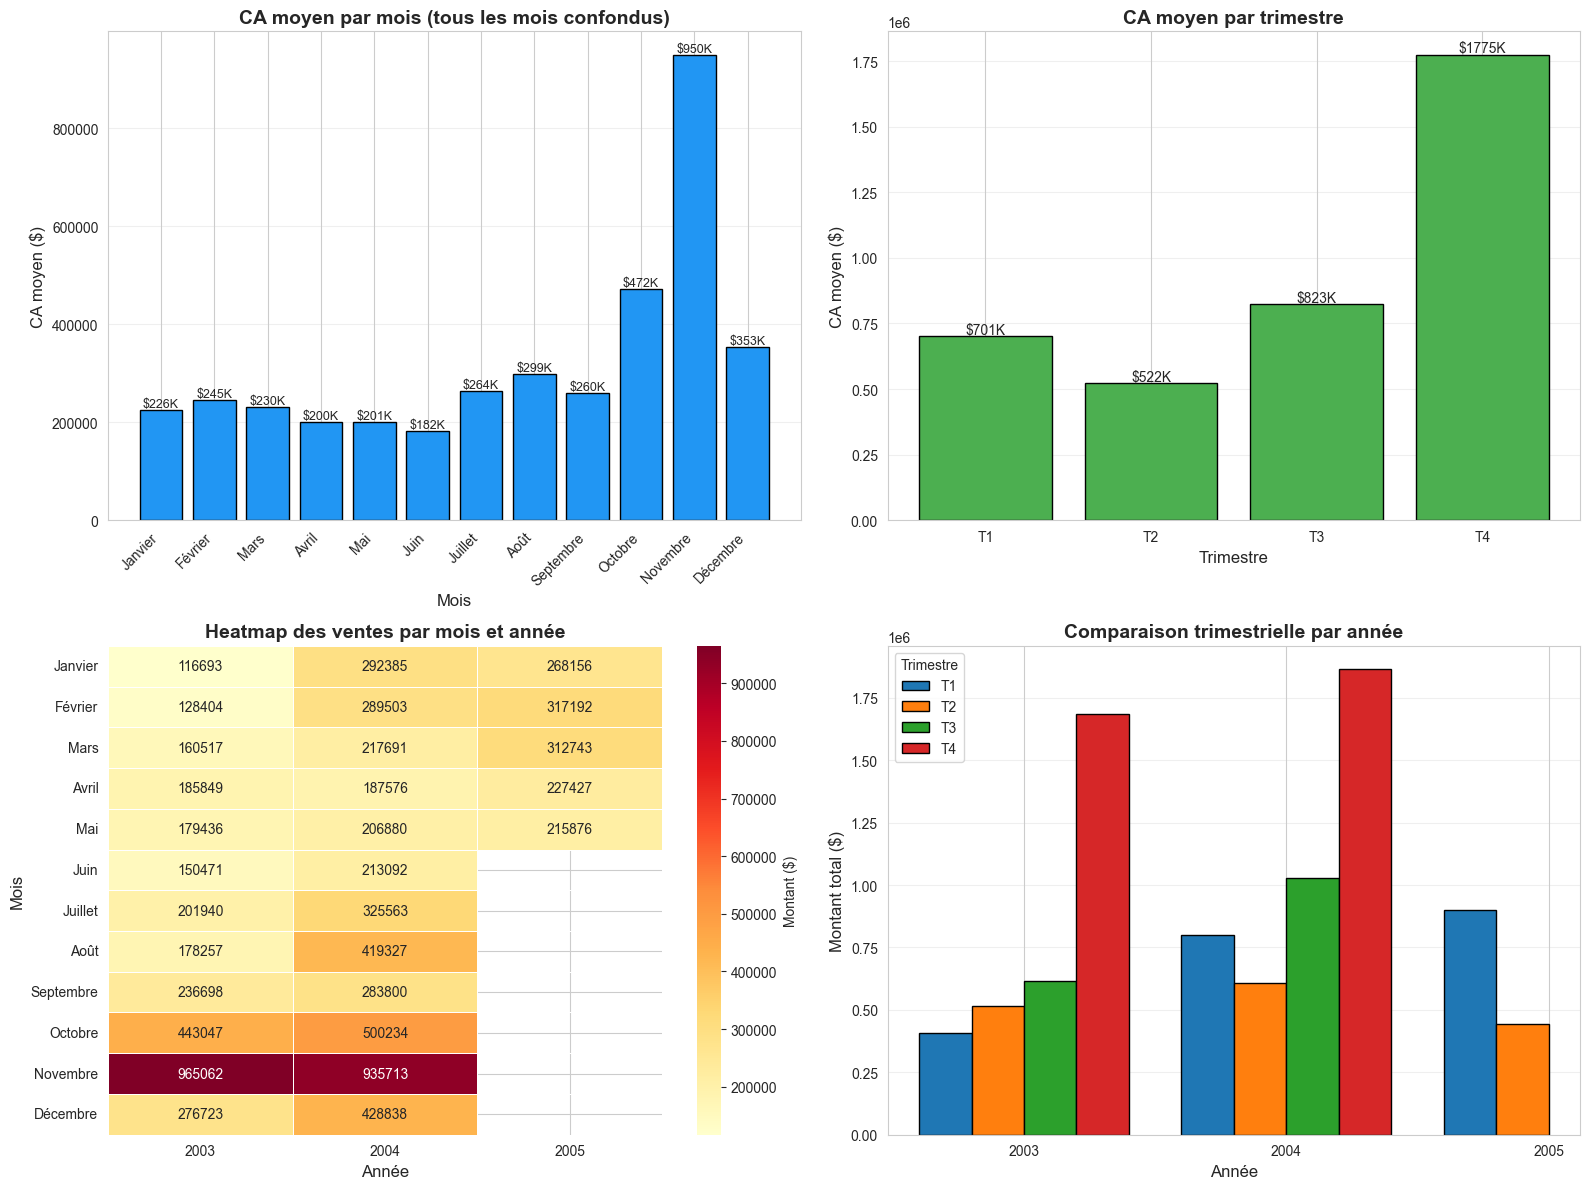

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. CA moyen par mois
monthly_ordered = monthly_stats.sort_index()
axes[0, 0].bar(range(1, 13), monthly_ordered['CA_moyen'], color='#2196F3', edgecolor='black')
axes[0, 0].set_xlabel('Mois', fontsize=12)
axes[0, 0].set_ylabel('CA moyen ($)', fontsize=12)
axes[0, 0].set_title('CA moyen par mois (tous les mois confondus)', fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(range(1, 13))
axes[0, 0].set_xticklabels([monthly_stats.loc[i, 'mois_nom'] for i in range(1, 13)], rotation=45, ha='right')
axes[0, 0].grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(monthly_ordered.iterrows(), 1):
    axes[0, 0].text(i, row['CA_moyen'], f'${row["CA_moyen"]/1000:.0f}K', 
                    ha='center', va='bottom', fontsize=9)

# 2. CA moyen par trimestre
quarterly_ordered = quarterly_stats.sort_index()
axes[0, 1].bar(quarterly_ordered['trimestre_nom'], quarterly_ordered['CA_moyen'], 
               color='#4CAF50', edgecolor='black')
axes[0, 1].set_xlabel('Trimestre', fontsize=12)
axes[0, 1].set_ylabel('CA moyen ($)', fontsize=12)
axes[0, 1].set_title('CA moyen par trimestre', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(quarterly_ordered.iterrows()):
    axes[0, 1].text(i, row['CA_moyen'], f'${row["CA_moyen"]/1000:.0f}K', 
                    ha='center', va='bottom', fontsize=10)

# 3. Heatmap des ventes par mois et année
df_pivot_month = df_monthly.pivot_table(
    values='montant_total', 
    index='mois', 
    columns='annee', 
    aggfunc='sum'
)
df_pivot_month.index = [monthly_stats.loc[i, 'mois_nom'] for i in df_pivot_month.index]

sns.heatmap(df_pivot_month, annot=True, fmt='.0f', cmap='YlOrRd', 
            cbar_kws={'label': 'Montant ($)'}, ax=axes[1, 0], linewidths=0.5)
axes[1, 0].set_xlabel('Année', fontsize=12)
axes[1, 0].set_ylabel('Mois', fontsize=12)
axes[1, 0].set_title('Heatmap des ventes par mois et année', fontsize=14, fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].tick_params(axis='y', rotation=0)

# 4. Comparaison trimestrielle par année
df_pivot_quarter = df_quarterly.pivot_table(
    values='montant_total', 
    index='trimestre', 
    columns='annee', 
    aggfunc='sum'
)
df_pivot_quarter.index = [f'T{int(i)}' for i in df_pivot_quarter.index]

x = np.arange(len(df_pivot_quarter.columns))
width = 0.2
for i, (idx, row) in enumerate(df_pivot_quarter.iterrows()):
    offset = (i - 1.5) * width
    axes[1, 1].bar(x + offset, row.values, width, label=idx, edgecolor='black')

axes[1, 1].set_xlabel('Année', fontsize=12)
axes[1, 1].set_ylabel('Montant total ($)', fontsize=12)
axes[1, 1].set_title('Comparaison trimestrielle par année', fontsize=14, fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(df_pivot_quarter.columns)
axes[1, 1].legend(title='Trimestre')
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## Interprétation des visualisations de saisonnalité

### Heatmap des ventes par mois et année

**Croissance interannuelle (2003 → 2004) :**
- **Janvier : +151%** ($117K → $292K) : Croissance exceptionnelle
- **Février : +125%** ($128K → $290K) : Forte croissance
- **Décembre : +55%** ($277K → $429K) : Croissance significative
- **Novembre : -3%** ($965K → $936K) : Légère baisse mais reste très élevé

**Insight** : Croissance généralisée sauf novembre qui stagne légèrement.

### Comparaison trimestrielle par année

**Évolution trimestrielle :**
- **T1** : Doublement en 2 ans ($0,4M → $0,8M → $0,9M) - Réduction de la saisonnalité
- **T2** : **-25% en 2005** ($0,6M → $0,45M) - **ALERTE** nécessitant action urgente
- **T3** : +67% en 2004 ($0,6M → $1,0M) - Stratégies estivales efficaces
- **T4** : Croissance stable (+9% en 2004) - Maintien de la dominance

**Recommandation prioritaire** : Investiguer et corriger la baisse de T2 2005.

## Identification des périodes fortes et faibles

Synthèse des mois et trimestres les plus performants et les moins performants.

In [ ]:
# Identification des top 3 et bottom 3 mois
top_months = monthly_stats.head(3)
bottom_months = monthly_stats.tail(3)

print("=" * 80)
print("MOIS FORTS (Top 3 par CA moyen)")
print("=" * 80)
for idx, row in top_months.iterrows():
    print(f"{row['mois_nom']} : ${row['CA_moyen']:,.2f} (Total: ${row['CA_total']:,.2f})")

print("\n" + "=" * 80)
print("MOIS FAIBLES (Bottom 3 par CA moyen)")
print("=" * 80)
for idx, row in bottom_months.iterrows():
    print(f"{row['mois_nom']} : ${row['CA_moyen']:,.2f} (Total: ${row['CA_total']:,.2f})")

print("\n" + "=" * 80)
print("TRIMESTRES (classés par CA moyen)")
print("=" * 80)
for idx, row in quarterly_stats.iterrows():
    print(f"{row['trimestre_nom']} : ${row['CA_moyen']:,.2f} (Total: ${row['CA_total']:,.2f})")

# Tableau récapitulatif
summary_df = pd.DataFrame({
    'Type': ['Mois le plus fort', 'Mois le plus faible', 'Trimestre le plus fort', 'Trimestre le plus faible'],
    'Période': [
        top_months.iloc[0]['mois_nom'],
        bottom_months.iloc[0]['mois_nom'],
        quarterly_stats.iloc[0]['trimestre_nom'],
        quarterly_stats.iloc[-1]['trimestre_nom']
    ],
    'CA moyen ($)': [
        top_months.iloc[0]['CA_moyen'],
        bottom_months.iloc[0]['CA_moyen'],
        quarterly_stats.iloc[0]['CA_moyen'],
        quarterly_stats.iloc[-1]['CA_moyen']
    ]
})

print("\n" + "=" * 80)
print("RÉSUMÉ DES PÉRIODES FORTES ET FAIBLES")
print("=" * 80)
display(summary_df)

MOIS FORTS (Top 3 par CA moyen)
Novembre : $950,387.25 (Total: $1,900,774.50)
Octobre : $471,640.54 (Total: $943,281.08)
Décembre : $352,780.71 (Total: $705,561.42)

MOIS FAIBLES (Bottom 3 par CA moyen)
Mai : $200,730.68 (Total: $602,192.05)
Avril : $200,283.92 (Total: $600,851.77)
Juin : $181,781.62 (Total: $363,563.23)

TRIMESTRES (classés par CA moyen)
T4 : $1,774,808.50 (Total: $3,549,617.00)
T3 : $822,792.85 (Total: $1,645,585.70)
T1 : $701,094.96 (Total: $2,103,284.89)
T2 : $522,202.35 (Total: $1,566,607.05)

RÉSUMÉ DES PÉRIODES FORTES ET FAIBLES


,Type,Période,CA moyen ($)
0,Mois le plus fort,Novembre,950387.25
1,Mois le plus faible,Mai,200730.68
2,Trimestre le plus fort,T4,1774808.50
3,Trimestre le plus faible,T2,522202.35


## Conclusion : Vision globale des tendances temporelles

### Synthèse exécutive

Cette analyse temporelle révèle **3 insights stratégiques majeurs** pour ClassicModels :

#### 1. Croissance régulière et durable
La tendance linéaire montre une **croissance de $7,195 par mois**, soit environ **$86,000 par an**. Cette croissance régulière indique une expansion saine et prévisible de l'entreprise.

**Implication** : L'entreprise est sur une bonne trajectoire. Les investissements et la planification peuvent être basés sur cette tendance de croissance.

#### 2. Saisonnalité très marquée
L'écart de **5,2x entre novembre (meilleur mois) et juin (mois le plus faible)** révèle une saisonnalité extrêmement prononcée. Le Q4 génère **3,4x plus que le Q2**.

**Implication** : La gestion opérationnelle doit être adaptée à ces cycles. Ne pas gérer la saisonnalité peut entraîner :
- Ruptures de stock en Q4
- Sur-stockage en Q2
- Problèmes de trésorerie
- Sous-optimisation des ressources

#### 3. Pattern de fin d'année dominant
Novembre, octobre et décembre sont les 3 meilleurs mois. Le Q4 est de loin le trimestre le plus performant.

**Implication** : **40-50% des efforts annuels** doivent être concentrés sur le Q4 pour maximiser les résultats.

### Plan d'action recommandé

#### Priorité 1 : Optimiser le Q4 (Oct-Déc)
- **Objectif** : Maximiser les ventes de fin d'année
- **Actions** :
  - Campagnes marketing dès septembre
  - Augmentation des stocks dès août
  - Renforcement des équipes (recrutements temporaires)
  - Promotions ciblées (Black Friday, Noël)
  - Communication client renforcée

#### Priorité 2 : Compenser le Q2 (Avr-Juin)
- **Objectif** : Réduire l'écart avec les autres trimestres
- **Actions** :
  - Événements et lancements produits en Q2
  - Promotions estivales
  - Développement de nouveaux segments (B2B, export)
  - Maintenance de la relation client (newsletters, offres spéciales)
  - Formation et développement interne

#### Priorité 3 : Lisser la saisonnalité
- **Objectif** : Réduire l'écart entre trimestres forts et faibles
- **Actions** :
  - Programmes de fidélité pour maintenir l'activité en Q2
  - Développement de produits/services complémentaires
  - Expansion géographique ou segmentaire
  - Stratégies de pré-commande pour lisser les ventes

### Métriques à suivre

- **Taux de croissance mensuel** : Maintenir > $7,000/mois
- **Ratio Q4/Q2** : Objectif de réduction de 3,4x à 2,5x en 2 ans
- **CA par trimestre** : Suivre l'évolution interannuelle
- **Variabilité mensuelle** : Réduire l'écart-type pour plus de prévisibilité

### Limites et considérations

- **Période d'analyse limitée** : 29 mois seulement, patterns à confirmer sur plus long terme
- **Contexte externe** : Facteurs économiques, concurrentiels non pris en compte
- **Évolution possible** : La saisonnalité peut évoluer avec le temps et les stratégies marketing